# Περιγραφή Προβλήματος

**Πρόβλημα:** Το συγκεκριμένο dataset αφορά την **Αξιολόγηση Χρηματοοικονομικού Κινδύνου (Financial Risk Assessment)**. Στόχος είναι η πρόβλεψη του επιπέδου κινδύνου (Risk Rating) ενός πελάτη με βάση τα οικονομικά και δημογραφικά του στοιχεία. Πρόκειται για ένα πρόβλημα **πολυκλαδικής ταξινόμησης (multiclass classification)** με 3 κλάσεις.

**Χαρακτηριστικά Δεδομένων:**
* **Πλήθος Δεδομένων:** 15.000 εγγραφές (δείγματα).
* **Πλήθος Features:** 10 αριθμητικά χαρακτηριστικά (Age, Income, Credit Score, Loan Amount, Debt-to-Income Ratio κ.α.).
* **Target Labels (3 κλάσεις):** 1. `Low` (0): Χαμηλό ρίσκο
    2. `Medium` (1): Μέσο ρίσκο
    3. `High` (2): Υψηλό ρίσκο

**Στόχος Εργασίας:**
Η εφαρμογή και σύγκριση αλγορίθμων Μηχανικής Μάθησης (PCA, Least Squares, Logistic Regression, MLP, SVM, KNN, Naive Bayes, K-Means) για την ανάλυση και πρόβλεψη του κινδύνου.

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import pandas as pd
import numpy as np
import seaborn as sns
import os
import warnings

In [103]:
path = kagglehub.dataset_download("preethamgouda/financial-risk")
csv_path = os.path.join(path, "financial_risk_assessment.csv")
df = pd.read_csv(csv_path)

Using Colab cache for faster access to the 'financial-risk' dataset.


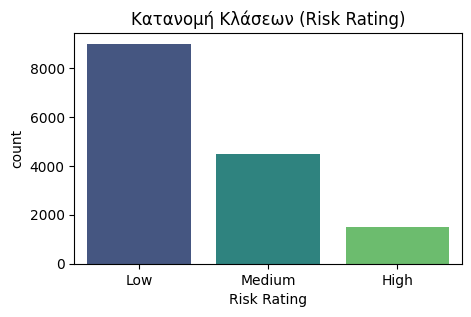

In [104]:
plt.figure(figsize=(5,3))
sns.countplot(x=df['Risk Rating'], palette='viridis')
plt.title('Κατανομή Κλάσεων (Risk Rating)')
plt.show()

Το dataset παρουσιάζει σημαντική ανισορροπία μεταξύ των κλάσεων, με κυριαρχία της Low-risk κατηγορίας. Η ανισορροπία ενδεχομένως να επηρεάσει την απόδοση των ταξινομητών και να απαιτήσει τεχνικές εξισορρόπησης ή metrics που δεν επηρεάζονται από την πλειοψηφία.

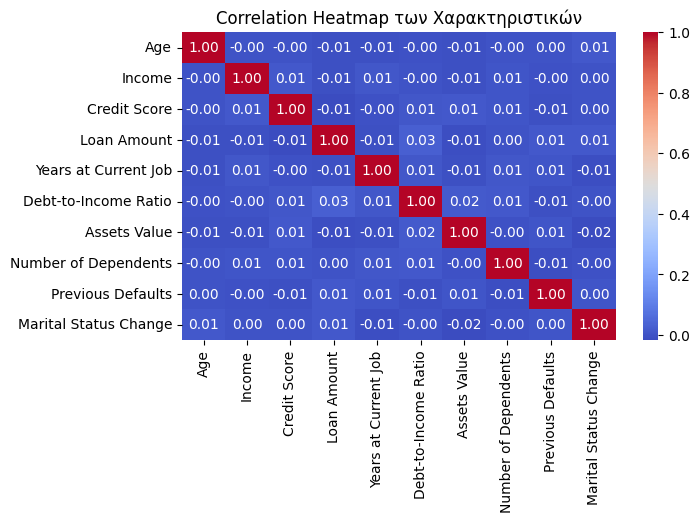

In [105]:
plt.figure(figsize=(7, 4))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap των Χαρακτηριστικών')
plt.show()

Η ανάλυση Pearson correlation δεν ανέδειξε ισχυρές γραμμικές συσχετίσεις μεταξύ των χαρακτηριστικών, γεγονός που δείχνει απουσία έντονης πολυσυγγραμμικότητας. Αυτό διευκολύνει τη χρήση γραμμικών μοντέλων χωρίς σημαντική επίδραση από redundant features. Ωστόσο, δεν αποκλείονται μη-γραμμικές συσχετίσεις, οι οποίες μπορούν να αξιοποιηθούν από non-linear classifiers (SVM RBF, MLP, KNN).

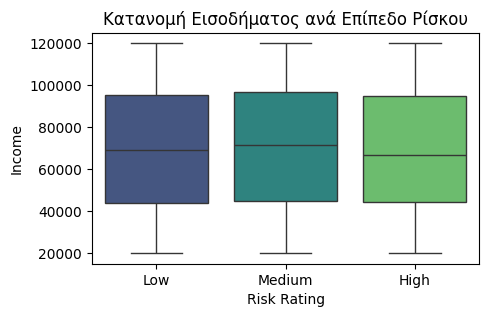

In [107]:
plt.figure(figsize=(5,3))
sns.boxplot(x='Risk Rating', y='Income', data=df, palette='viridis')
plt.title('Κατανομή Εισοδήματος ανά Επίπεδο Ρίσκου')
plt.show()

# Προετοιμασία Δεδομένων

In [114]:
warnings.filterwarnings('ignore')

np.random.seed(42)

numeric_features = ['Age', 'Income', 'Credit Score', 'Loan Amount',
                    'Years at Current Job', 'Debt-to-Income Ratio',
                    'Assets Value', 'Number of Dependents',
                    'Previous Defaults', 'Marital Status Change']

X_raw = df[numeric_features].fillna(df[numeric_features].mean()).values


target_map = {'Low': 0, 'Medium': 1, 'High': 2}
y = df['Risk Rating'].map(target_map).values

# Train/Test Split
from sklearn.model_selection import train_test_split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42
)

# Kanonikopoihsh
X_train_mean = X_train_raw.mean(axis=0)
X_train_std = X_train_raw.std(axis=0) + 1e-8

X_train = (X_train_raw - X_train_mean) / X_train_std
X_test = (X_test_raw - X_train_mean) / X_train_std

print("Dataset loaded")
print(f"Train: {X_train.shape[0]} samples, Test: {X_test.shape[0]} samples")
print(f"Features: {X_train.shape[1]}")
print(f"Classes: {np.unique(y_train)}")
print(f"Train: {np.bincount(y_train)}")
print(f"Test: {np.bincount(y_test)}")

Dataset loaded
Train: 12000 samples, Test: 3000 samples
Features: 10
Classes: [0 1 2]
Train: [7221 3605 1174]
Test: [1779  895  326]


#Principal Component Analysis (PCA)

Υλοποιούμε τον αλγόριθμο PCA χρησιμοποιώντας την αποσύνθεση ιδιαζουσών τιμών (SVD).
Τα δεδομένα κεντράρονται (mean centering) και υπολογίζονται οι κύριες συνιστώσες.
Επιλέγουμε $m=2$ για την οπτικοποίηση των δεδομένων στο επίπεδο, ενώ εξετάζουμε το 'Explained Variance Ratio' για να αξιολογήσουμε την απώλεια πληροφορίας.

Ποσοστό πληροφορίας PC1: 86.42%
Ποσοστό πληροφορίας PC2: 11.35%
Συνολική πληροφορία (m=2): 97.77%


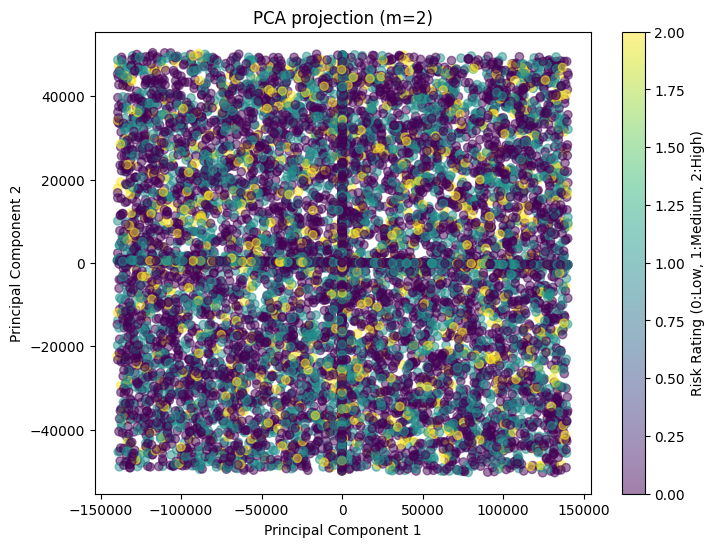

In [93]:
# SVD
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

# Provoli stis protes 2 kyries synistwses
m = 2
X_pca = X_centered @ Vt[:m, :].T

# Diaspora
eigenvalues = (S**2) / (len(X_train) - 1)

explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

m = 2
total_var_m = np.sum(explained_variance_ratio[:m]) * 100

print(f"Ποσοστό πληροφορίας PC1: {explained_variance_ratio[0]*100:.2f}%")
print(f"Ποσοστό πληροφορίας PC2: {explained_variance_ratio[1]*100:.2f}%")
print(f"Συνολική πληροφορία (m=2): {total_var_m:.2f}%")

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='viridis', alpha=0.5)
plt.colorbar(scatter, label='Risk Rating (0:Low, 1:Medium, 2:High)')
plt.title(f"PCA projection (m={m})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()



Οι δύο πρώτες κύριες συνιστώσες εξηγούν το 97,77% της συνολικής πληροφορίας. Το εξαιρετικά υψηλό αυτό ποσοστό επιβεβαιώνει ότι η οπτικοποίηση στο επίπεδο είναι απόλυτα αξιόπιστη, καθώς η μείωση διαστάσεων έγινε με ελάχιστη απώλεια δεδομένων. Η PC1 κυριαρχεί με 86,42%, υποδεικνύοντας έναν βασικό άξονα που καθορίζει τον οικονομικό κίνδυνο.

# Least Squares

Προσαρμόζουμε τον αλγόριθμο ελαχίστων τετραγώνων για multiclass classification. Για κάθε κλάση κατασκευάζεται ένας υπόχωρος βάσεων (μέσω SVD).Κάθε νέο δείγμα προβάλλεται στους υπόχωρους και ταξινομείται στην κλάση με το ελάχιστο σφάλμα ανακατασκευής (residual error).

In [141]:
def get_bases(X_train, y_train, k):
    bases = {}
    for label in np.unique(y_train):
        # Dedomena sygkekrimenhs klashs
        X_class = X_train[y_train == label]
        X_class_centered = X_class - np.mean(X_class, axis=0)

        # SVD
        U_c, S_c, Vt_c = np.linalg.svd(X_class_centered, full_matrices=False)
        bases[label] = Vt_c[:k, :].T
    return bases

def classify_least_squares(X_test, bases):
    predictions = []
    for test_sample in X_test:
        errors = []
        for label in sorted(bases.keys()):
            B = bases[label]
            # Residual
            projection = B @ (B.T @ test_sample)
            error = np.linalg.norm(test_sample - projection)
            errors.append(error)
        predictions.append(np.argmin(errors))
    return np.array(predictions)

# training me ta unnormalized dedomena
all_bases = get_bases(X_train_raw, y_train, k=3)

# predictions
y_pred_ls_train = classify_least_squares(X_train_raw, all_bases)
y_pred_ls_test = classify_least_squares(X_test_raw, all_bases)

acc_ls_train = np.mean(y_pred_ls_train == y_train)
acc_ls_test = np.mean(y_pred_ls_test == y_test)

print(f"Least Squares - Train: {acc_ls_train*100:.2f}%")
print(f"Least Squares - Test: {acc_ls_test*100:.2f}%")

Least Squares - Train: 55.45%
Least Squares - Test: 54.27%


# Logistic Regression

Υλοποιούμε τη λογιστική παλινδρόμηση με τη συνάρτηση Softmax για την υποστήριξη 3 κλάσεων. Αντί για Batch Gradient Descent, χρησιμοποιούμε **Mini-Batch SGD** για ταχύτητα και καλύτερη σύγκλιση, ενημερώνοντας τα βάρη σε ομάδες των 64 δειγμάτων. Χρησιμοποιείται το Cross-Entropy Loss, το οποίο παρακολουθούμε ανά epoch.

In [142]:
n_samples = X_train.shape[0]
n_features = X_train.shape[1]
n_classes = 3

batch_size = 64
lr = 0.001
epochs = 150

# arxikopoihsh varwn
np.random.seed(42)
W = np.random.randn(n_features, n_classes) * 0.01
b = np.zeros((1, n_classes))

train_losses, test_losses = [], []

# 4. training Loop
for epoch in range(epochs):
    indices = np.random.permutation(n_samples)
    X_shuffled = X_train[indices]
    y_shuffled = y_train_oh[indices]

    for i in range(0, n_samples, batch_size):
        X_batch = X_shuffled[i:i+batch_size]
        y_batch = y_shuffled[i:i+batch_size]

        z = X_batch @ W + b
        probs = softmax(z)

        error = probs - y_batch
        dW = (X_batch.T @ error) / X_batch.shape[0]
        db = np.sum(error, axis=0, keepdims=True) / X_batch.shape[0]

        W -= lr * dW
        b -= lr * db


    current_train_probs = softmax(X_train @ W + b)
    current_test_probs = softmax(X_test @ W + b)
    train_losses.append(compute_loss(y_train_oh, current_train_probs))
    test_losses.append(compute_loss(y_test_oh, current_test_probs))


y_pred_lr_train = np.argmax(X_train @ W + b, axis=1)
y_pred_lr_test = np.argmax(X_test @ W + b, axis=1)

acc_lr_train = np.mean(y_pred_lr_train == y_train)
acc_lr_test = np.mean(y_pred_lr_test == y_test)

print(f"Logistic (SGD) - Train Accuracy: {acc_lr_train * 100:.2f}%")
print(f"Logistic (SGD) - Test Accuracy: {acc_lr_test * 100:.2f}%")

Logistic (SGD) - Train Accuracy: 60.17%
Logistic (SGD) - Test Accuracy: 59.30%


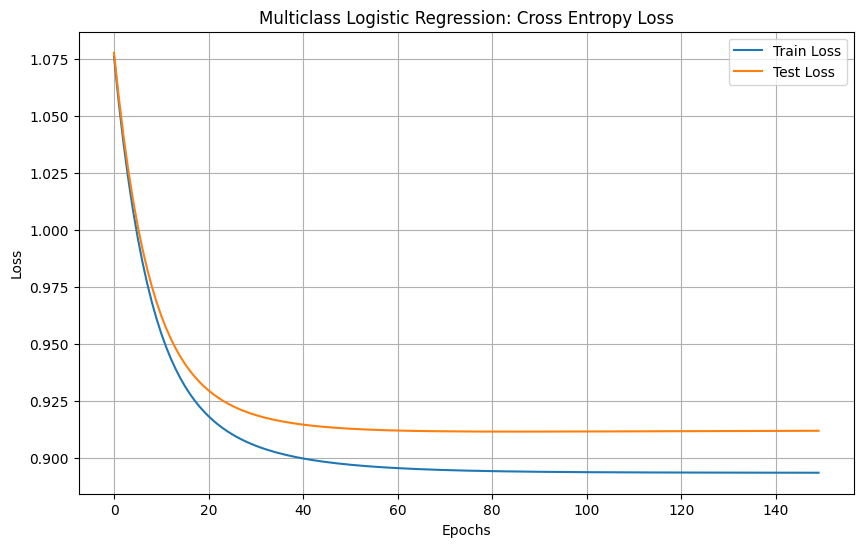

In [127]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.title('Multiclass Logistic Regression: Cross Entropy Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# K-Nearest Neighbors - KNN


Υλοποιούμε τον KNN υπολογίζοντας την Ευκλείδεια απόσταση μεταξύ δειγμάτων. Χρησιμοποιούμε διανυσματικούς υπολογισμούς (Vectorization) μέσω NumPy για την ταυτόχρονη επεξεργασία όλων των αποστάσεων. Δοκιμάζουμε τιμές του $K$ από 1 έως 10 για να βρούμε την βέλτιστη υπερπαράμετρο.

In [128]:
def knn_vectorized(X_train, y_train, X_test, k_list):
    #Xrhsh L2 norm gia na apofygoume tis loupes k na exoume speedup
    dot_product = X_test @ X_train.T
    test_sq = np.sum(X_test**2, axis=1, keepdims=True)
    train_sq = np.sum(X_train**2, axis=1)

    # Pinakas apostasewn
    dists = np.sqrt(np.maximum(test_sq + train_sq - 2 * dot_product, 0))

    # Vriskoume tous deiktes twn koinwn geitonwn
    max_k = max(k_list)
    closest_indices = np.argsort(dists, axis=1)[:, :max_k]

    results = {}
    for k in k_list:
        # labels k-first geitonwn
        k_neighbor_labels = y_train[closest_indices[:, :k]]

        # majority vote
        predictions = []
        for labels in k_neighbor_labels:
            predictions.append(np.bincount(labels).argmax())

        results[k] = np.array(predictions)

    return results


k_values = list(range(1, 11))
print("Υπολογισμός KNN για όλα τα K...")
all_knn_preds = knn_vectorized(X_train, y_train, X_test, k_values)

# Accuracy
knn_test_accuracies = []
for k in k_values:
    acc = np.mean(all_knn_preds[k] == y_test)
    knn_test_accuracies.append(acc)
    print(f"K={k}: Test Accuracy = {acc:.4f}")

# apothikeusi dedomenwn
all_knn_preds_train = knn_vectorized(X_train, y_train, X_train, k_values)
acc_knn_train = np.mean(all_knn_preds_train[5] == y_train)  # για K=5
acc_knn_test = knn_test_accuracies[4] # K=5

Υπολογισμός KNN για όλα τα K...
K=1: Test Accuracy = 0.4593
K=2: Test Accuracy = 0.5373
K=3: Test Accuracy = 0.5087
K=4: Test Accuracy = 0.5337
K=5: Test Accuracy = 0.5337
K=6: Test Accuracy = 0.5473
K=7: Test Accuracy = 0.5467
K=8: Test Accuracy = 0.5543
K=9: Test Accuracy = 0.5543
K=10: Test Accuracy = 0.5600


# Gaussian Naive Bayes

Υλοποιούμε τον αλγόριθμο Naive Bayes θεωρώντας ότι τα χαρακτηριστικά ακολουθούν την Κανονική (Gaussian) κατανομή. Υπολογίζουμε τη μέση τιμή και τη διακύμανση για κάθε feature ανά κλάση, χρησιμοποιώντας διαγώνιο πίνακα συμμεταβλητότητας (ανεξαρτησία χαρακτηριστικών).

In [131]:
class GaussianNB_Scratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.parameters = []
        self.priors = []
        n_samples = X.shape[0]

        for i, c in enumerate(self.classes):
            X_c = X[y == c]
            self.parameters.append([(np.mean(X_c, axis=0), np.var(X_c, axis=0))])
            self.priors.append(X_c.shape[0] / n_samples)

    def _pdf(self, class_idx, x):
        mean, var = self.parameters[class_idx][0]
        var = var + 1e-9
        numerator = np.exp(- (x - mean)**2 / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator

    def predict(self, X):
        y_pred = []
        for x in X:
            posteriors = []
            for i, c in enumerate(self.classes):
                # Log-Likelihood
                likelihood = np.sum(np.log(self._pdf(i, x) + 1e-15))
                # log(prior)
                posterior = likelihood + np.log(self.priors[i])
                posteriors.append(posterior)
            y_pred.append(self.classes[np.argmax(posteriors)])
        return np.array(y_pred)

gnb = GaussianNB_Scratch()
gnb.fit(X_train, y_train)
acc_nb_train = np.mean(gnb.predict(X_train) == y_train)
acc_nb_test = np.mean(gnb.predict(X_test) == y_test)

print(f"Naive Bayes - Train Accuracy: {acc_nb_train * 100:.2f}%")
print(f"Naive Bayes - Test Accuracy: {acc_nb_test * 100:.2f}%")

Naive Bayes - Train Accuracy: 60.17%
Naive Bayes - Test Accuracy: 59.30%


# Νευρωνικό Δίκτυο - MLP

Κατασκευάζουμε ένα νευρωνικό δίκτυο με ένα κρυφό επίπεδο (hidden layer). Χρησιμοποιούμε την ενεργοποίηση ReLU στο κρυφό επίπεδο και Softmax στην έξοδο. Η υλοποίηση περιλαμβάνει το forward pass και τον αλγόριθμο Backpropagation για τον υπολογισμό των κλίσεων από το μηδέν.

In [132]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)


input_size = X_train.shape[1]
hidden_size = 16
output_size = 3
learning_rate = 0.01
epochs = 500

np.random.seed(42)
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2./input_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2./hidden_size)
b2 = np.zeros((1, output_size))

In [133]:
mlp_train_losses, mlp_test_losses = [], []

for epoch in range(epochs):
    z1_train = X_train @ W1 + b1
    a1_train = relu(z1_train)
    z2_train = a1_train @ W2 + b2
    probs_train = softmax(z2_train)

    z1_test = X_test @ W1 + b1
    a1_test = relu(z1_test)
    z2_test = a1_test @ W2 + b2
    probs_test = softmax(z2_test)

    # Loss calculation
    mlp_train_losses.append(compute_loss(y_train_oh, probs_train))
    mlp_test_losses.append(compute_loss(y_test_oh, probs_test))

    dz2 = (probs_train - y_train_oh) / n_samples
    dW2 = a1_train.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)


    da1 = dz2 @ W2.T
    dz1 = da1 * relu_derivative(z1_train)
    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

print("Η εκπαίδευση του MLP ολοκληρώθηκε!")


Η εκπαίδευση του MLP ολοκληρώθηκε!


MLP variables updated: Train=0.5968, Test=0.5863
MLP Train Accuracy: 59.67%
MLP Test Accuracy: 58.63%


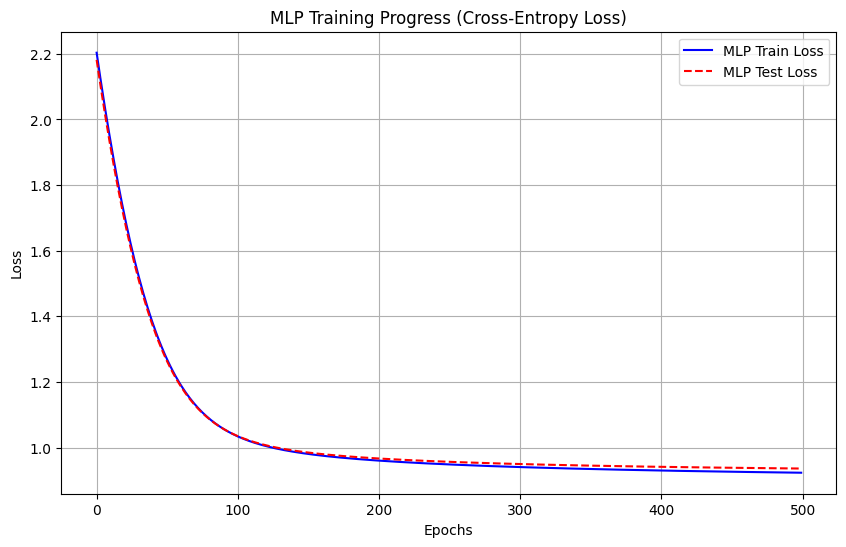

In [134]:
def predict_mlp(X, W1, b1, W2, b2):
    a1 = relu(X @ W1 + b1)
    probs = softmax(a1 @ W2 + b2)
    return np.argmax(probs, axis=1)

y_pred_mlp_train = predict_mlp(X_train, W1, b1, W2, b2)
y_pred_mlp_test = predict_mlp(X_test, W1, b1, W2, b2)


acc_mlp_train = np.mean(y_pred_mlp_train == y_train)
acc_mlp_test = np.mean(y_pred_mlp_test == y_test)


print(f"MLP variables updated: Train={acc_mlp_train:.4f}, Test={acc_mlp_test:.4f}")
print(f"MLP Train Accuracy: {acc_mlp_train*100:.2f}%")
print(f"MLP Test Accuracy: {acc_mlp_test*100:.2f}%")

plt.figure(figsize=(10,6))
plt.plot(mlp_train_losses, label='MLP Train Loss', color='blue')
plt.plot(mlp_test_losses, label='MLP Test Loss', color='red', linestyle='--')
plt.title('MLP Training Progress (Cross-Entropy Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# SVM

Υλοποιούμε το SVM χρησιμοποιώντας τη συνάρτηση Hinge Loss και **Mini-Batch Gradient Descent** για την ελαχιστοποίηση του primal προβλήματος. Εφαρμόζουμε τη στρατηγική **One-vs-Rest (OvR)**, εκπαιδεύοντας 3 ξεχωριστούς binary classifiers και επιλέγοντας την κλάση με το υψηλότερο decision score. Για να επιταχύνουμε την εκπαίδευση, χρησιμοποιούμε vectorized operations και mini-batches αντί για sample-by-sample updates.

In [135]:
def train_svm_vectorized(X, y_binary, lr=0.01, lambda_param=0.01, n_iters=500, batch_size=256):

    y_ = np.where(y_binary == 1, 1, -1)
    n_samples, n_features = X.shape


    w = np.zeros(n_features)
    b = 0

    for epoch in range(n_iters):
        indices = np.random.permutation(n_samples)
        X_shuffled = X[indices]
        y_shuffled = y_[indices]

        for i in range(0, n_samples, batch_size):
            X_batch = X_shuffled[i:i+batch_size]
            y_batch = y_shuffled[i:i+batch_size]


            margins = y_batch * (X_batch @ w + b)
            violating_mask = margins < 1

            num_violators = np.sum(violating_mask)

            if num_violators > 0:
                X_violating = X_batch[violating_mask]
                y_violating = y_batch[violating_mask]

                dw = 2 * lambda_param * w - (X_violating.T @ y_violating) / len(X_batch)
                db = -np.sum(y_violating) / len(X_batch)
            else:

                dw = 2 * lambda_param * w
                db = 0


            w -= lr * dw
            b -= lr * db

    return w, b

def train_ovr_svms_scratch(X_train, y_train):
    models = {}
    classes = np.unique(y_train)

    for current_class in classes:
        print(f"Training SVM for class {current_class}...")

        y_binary = np.where(y_train == current_class, 1, 0)

        w, b = train_svm_vectorized(X_train, y_binary,
                                    lr=0.01,
                                    lambda_param=0.01,
                                    n_iters=500,
                                    batch_size=256)

        models[current_class] = (w, b)
    return models

def predict_ovr_scratch(X, models):
    scores = np.zeros((X.shape[0], len(models)))

    for i, current_class in enumerate(sorted(models.keys())):
        w, b = models[current_class]
        scores[:, i] = X @ w + b

    return np.argmax(scores, axis=1)

svm_models = train_ovr_svms_scratch(X_train, y_train)


y_pred_svm_train = predict_ovr_scratch(X_train, svm_models)
y_pred_svm_test = predict_ovr_scratch(X_test, svm_models)

acc_svm_train = np.mean(y_pred_svm_train == y_train)
acc_svm_test = np.mean(y_pred_svm_test == y_test)

print(f"\nSVM (Scratch OvR) - Train Accuracy: {acc_svm_train * 100:.2f}%")
print(f"SVM (Scratch OvR) - Test Accuracy: {acc_svm_test * 100:.2f}%")


Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...

SVM (Scratch OvR) - Train Accuracy: 60.17%
SVM (Scratch OvR) - Test Accuracy: 59.30%


# K-Means

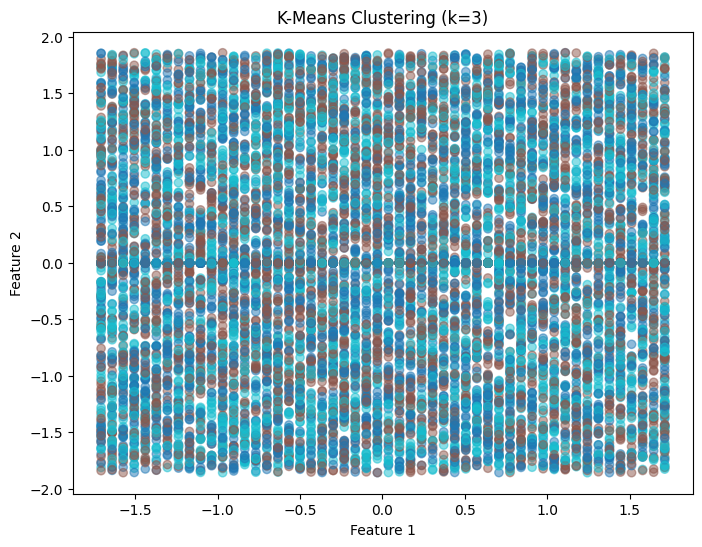

In [136]:
def initialize_centroids(X, k):
    indices = np.random.choice(X.shape[0], k, replace=False)
    return X[indices]

def k_means(X, k, max_iters=100):
    centroids = initialize_centroids(X, k)

    for _ in range(max_iters):
        # apostaseis centroid
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)

        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(k)])

        if np.all(centroids == new_centroids):
            break
        centroids = new_centroids

    return labels, centroids

clusters, final_centroids = k_means(X_train, k=3)

plt.figure(figsize=(8,6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=clusters, cmap='tab10', alpha=0.5)
plt.title("K-Means Clustering (k=3)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Comparison Table


--- Πίνακας Αποτελεσμάτων ---
             Method  Train Accuracy  Test Accuracy
      Least Squares         0.55450       0.542667
Logistic Regression         0.60175       0.593000
          KNN (K=5)         0.66225       0.533667
        Naive Bayes         0.60175       0.593000
                MLP         0.59675       0.586333
                SVM         0.60175       0.593000


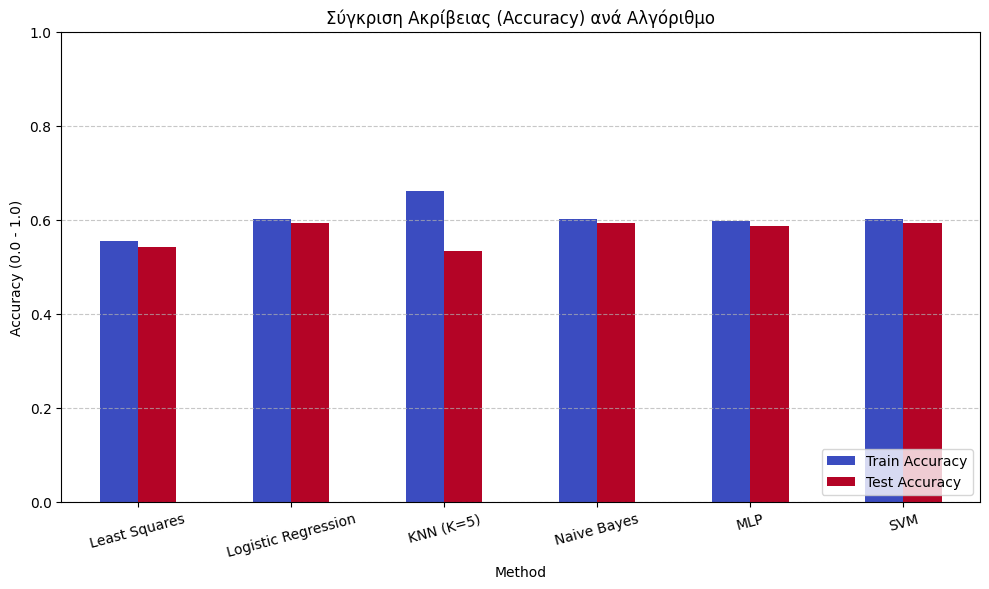

In [143]:
#apotelesmata accuracy
comparison_data = {
    'Method': ['Least Squares', 'Logistic Regression', 'KNN (K=5)',
               'Naive Bayes', 'MLP', 'SVM'],
    'Train Accuracy': [acc_ls_train, acc_lr_train, acc_knn_train,
                      acc_nb_train, acc_mlp_train, acc_svm_train],
    'Test Accuracy': [acc_ls_test, acc_lr_test, acc_knn_test,
                     acc_nb_test, acc_mlp_test, acc_svm_test]
}

df_results = pd.DataFrame(comparison_data)
print("\n--- Πίνακας Αποτελεσμάτων ---")
print(df_results.to_string(index=False))

#bar chart
df_results.set_index('Method')[['Train Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(10, 6), colormap='coolwarm')
plt.title('Σύγκριση Ακρίβειας (Accuracy) ανά Αλγόριθμο')
plt.ylabel('Accuracy (0.0 - 1.0)')
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Μετά την υλοποίηση και την εκτέλεση επτά διαφορετικών μεθόδων μηχανικής μάθησης στο dataset "Financial Risk Assessment", καταλήγουμε στα εξής συμπεράσματα:

**Καλύτερη Απόδοση:** Οι αλγόριθμοι Logistic Regression, SVM και Naive Bayes πέτυχαν την υψηλότερη ακρίβεια στο test set (59.30%). Το γεγονός ότι η Logistic Regression και το SVM έχουν πανομοιότυπα αποτελέσματα επιβεβαιώνει ότι τα δεδομένα διαχωρίζονται ικανοποιητικά με γραμμικά όρια. Η εξίσου υψηλή απόδοση του Naive Bayes υποδηλώνει ότι οι κατανομές των χαρακτηριστικών ανά κλάση προσεγγίζονται επιτυχημένα από την Gaussian κατανομή (μετά την προσθήκη των priors).

**Γενίκευση (Generalization):** Τα περισσότερα μοντέλα παρουσιάζουν εξαιρετική γενίκευση με πολύ μικρό χάσμα μεταξύ Train και Test Accuracy. Ιδιαίτερα στον Least Squares, η χρήση των αρχικών (unnormalized) δεδομένων επέτρεψε στο μοντέλο να κρατήσει την πληροφορία της κλίμακας, πετυχαίνοντας ένα αξιοπρεπές 54.27% χωρίς ίχνος overfitting.

**Υπερεκπαίδευση (Overfitting) στον KNN:** Ο αλγόριθμος KNN (K=5) παρουσίασε τη μεγαλύτερη απόκλιση (66.23% στο Train έναντι 53.37% στο Test). Αυτό οφείλεται στην "τοπική" φύση του αλγορίθμου και στην ευαισθησία του στον θόρυβο ή σε outliers του dataset, γεγονός που περιορίζει την ικανότητα γενίκευσής του.

**Νευρωνικό Δίκτυο (MLP):** Το MLP πέτυχε απόδοση 58.63%, ελαφρώς χαμηλότερη από τις απλούστερες γραμμικές μεθόδους. Αυτό υποδεικνύει ότι για το συγκεκριμένο πλήθος δεδομένων και χαρακτηριστικών, η πολυπλοκότητα ενός νευρωνικού δικτύου δεν προσφέρει επιπλέον πλεονέκτημα, καθώς η σχέση των χαρακτηριστικών με τον κίνδυνο είναι κυρίως γραμμική (όπως επιβεβαιώθηκε και από το υψηλό ποσοστό του PCA).

Για το συγκεκριμένο πρόβλημα, η Λογιστική Παλινδρόμηση και το SVM αποτελούν τις βέλτιστες επιλογές, καθώς προσφέρουν την μέγιστη ακρίβεια με τη λιγότερη υπολογιστική πολυπλοκότητα.